In [1]:
import pandas as pd

In [2]:
nhanes = pd.read_csv

In [3]:
nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

/tmp/xpython_320/3701312428.py:1: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes = pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


In [4]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

In [5]:
children.shape

(2833, 197)

In [6]:
children["AgeInYearsAtScreening"].describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [7]:
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

<Axes: >

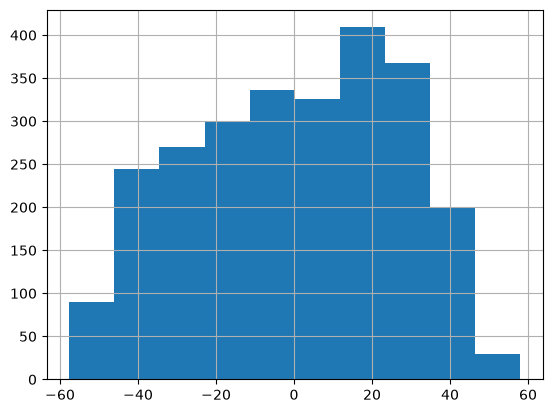

In [8]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

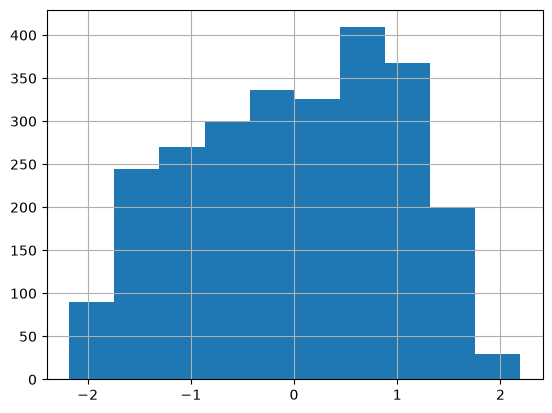

In [9]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean()) / children["StandingHeightCm"].std()).hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

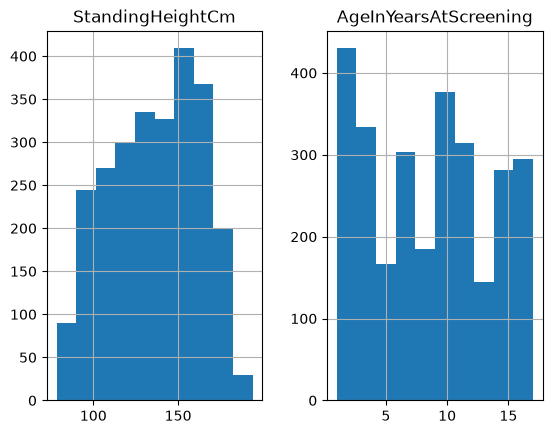

In [10]:
children[["StandingHeightCm", "AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

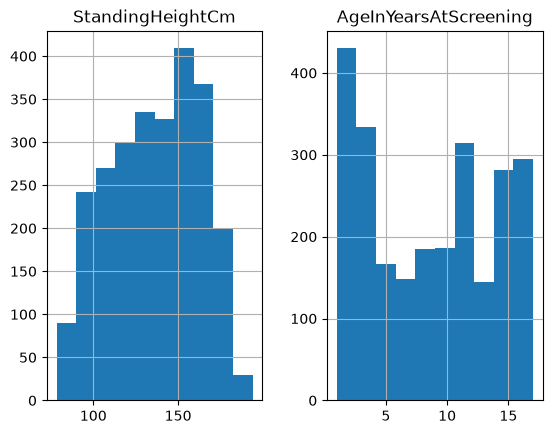

In [11]:
children[["StandingHeightCm", "AgeInYearsAtScreening"]].replace([7, 9, 77, 99, 777, 999, 7777, 9999], pd.NA).astype("Float64").hist()

In [12]:
import seaborn as sns
import pingouin as pg

<class 'ModuleNotFoundError'>: No module named 'pingouin'

In [13]:
%pip install seaborn pingouin

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 5.2 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 5.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pingouin]7/8 [pingouin]ls]
Note: you may need to restart the kernel to use updated packages.


In [14]:
import seaborn as sns
import pingouin as pg

In [15]:
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"], remove_na=True)

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

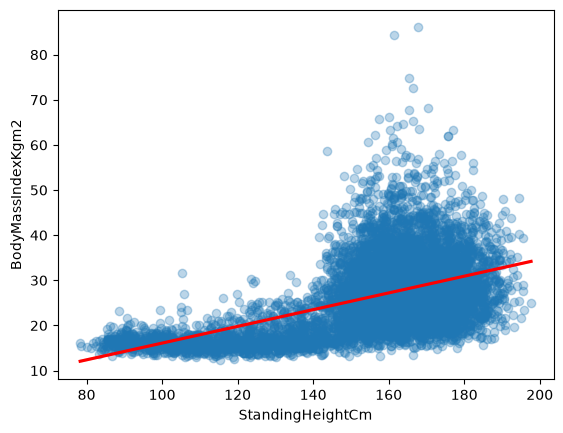

In [16]:
sns.regplot(data=nhanes, x="StandingHeightCm", y="BodyMassIndexKgm2",
            scatter_kws={"color": "C0", "alpha": 0.3},
            line_kws={"color": "red"})

In [17]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt